In [ ]:
# question 1 

In [8]:
import pandas as pd

In [3]:
import numpy as np

In [4]:
import matplotlib.pyplot as plt

In [5]:
# load data 
df = pd.read_csv('automobileEDA.csv')

In [9]:
# checking shape and columns 
print(df.shape)

(201, 29)


The dataset has 201 rows and 29 columns 

In [14]:
print(df.columns.tolist())

['symboling', 'normalized-losses', 'make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'city-L/100km', 'horsepower-binned', 'diesel', 'gas']


In [ ]:
# checking missing values 
print(df.isna().sum())

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64


There were 4 missing values for stroke and 1 for horsepower-binned in the dataset

In [ ]:
# checking for duplicates 
print (df.duplicated().sum())

0


The results show 0 duplicates, meaning no repeated rows in the dataset

In [18]:
# Cleaning missing values 
df= df.replace ('?' , pd.NA)

In [21]:
#convert stroke to number  and fill
df['stroke']=pd.to_numeric(df['stroke'],errors='coerce')
df['stroke']=df['stroke'].fillna(df['stroke'].median())

In [23]:
# fill horsepower 
df['horsepower-binned']=df['horsepower-binned'].fillna(df['horsepower-binned'].mode()[0])

In [24]:
# checking for no more missing valuves 
print(df.isna().sum())

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    0
diesel               0
gas                  0
dtype: int64


Before cleaning , there were 4 missing values for stroke and 1 for horsepower-binned marked as ?, after replacing ? with NA and filling medianand mode, all missing values are handled

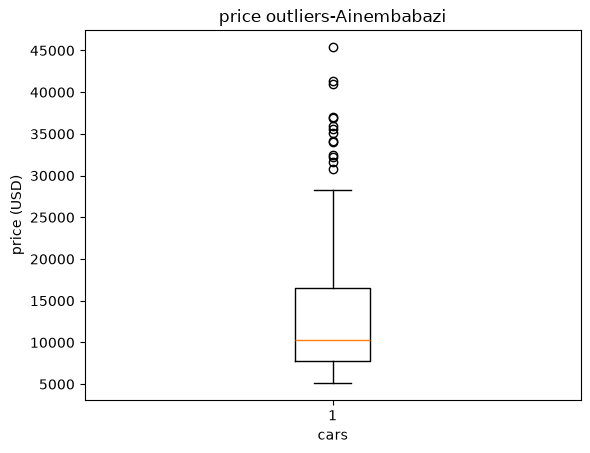

In [11]:
#checking for outliers
import matplotlib.pyplot as plt
plt.boxplot(df['price'])
plt.title('price outliers-Ainembabazi')
plt.xlabel('cars')
plt.ylabel('price (USD)')
plt.show()

The price variable has outliers above 30,000 USD as seen in the boxplot. Most cars are priced between 8,000 and 17,000 USD. The median is around 10,000 USD .The outliers are above 30,000 up to 45,000 

In [33]:
#saving the cleaned file
df.to_csv('Ainembabazi_Data.csv',index=False)
print("Saved as Ainembabazi_Data.csv")


Saved as Ainembabazi_Data.csv


In [ ]:
# Question 2
## Descriptive statitsis 
import pandas as pd
df=pd.read_csv('Ainembabazi.Data.csv')
print(df.describe())

        symboling  normalized-losses  wheel-base      length       width  \
count  201.000000          201.00000  201.000000  201.000000  201.000000   
mean     0.840796          122.00000   98.797015    0.837102    0.915126   
std      1.254802           31.99625    6.066366    0.059213    0.029187   
min     -2.000000           65.00000   86.600000    0.678039    0.837500   
25%      0.000000          101.00000   94.500000    0.801538    0.890278   
50%      1.000000          122.00000   97.000000    0.832292    0.909722   
75%      2.000000          137.00000  102.400000    0.881788    0.925000   
max      3.000000          256.00000  120.900000    1.000000    1.000000   

           height  curb-weight  engine-size        bore      stroke  \
count  201.000000   201.000000   201.000000  201.000000  201.000000   
mean    53.766667  2555.666667   126.875622    3.330692    3.257562   
std      2.447822   517.296727    41.546834    0.268072    0.316082   
min     47.800000  1488.000000 

The dataset contains 201 cars. Average price 13,207 USD with standard deviation of 7,947 showing high variation. Minimun price is 5,118 and maximum price 45,400. 25% of the cars cost below 7,775 and 75% also cost 16,500, median is 10,295.
City fuel consumption mean is 9.94 L/100km. Diesel mean 0.09 shows 9% are diesel, 90% are gas. Horsepower mean is 103 and engine-size mean 126 .

In [30]:
#Counts for categorical values
print(df['body-style'].value_counts())
print(df['fuel-system'].value_counts())
print(df['num-of-doors'].value_counts())

body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64
fuel-system
mpfi    92
2bbl    64
idi     20
1bbl    11
spdi     9
4bbl     3
mfi      1
spfi     1
Name: count, dtype: int64
num-of-doors
four    115
two      86
Name: count, dtype: int64


Sedan (94) is the most common body-style ,mpfi(92) is the most common fuel-system and four-door(115) is more common than two-door

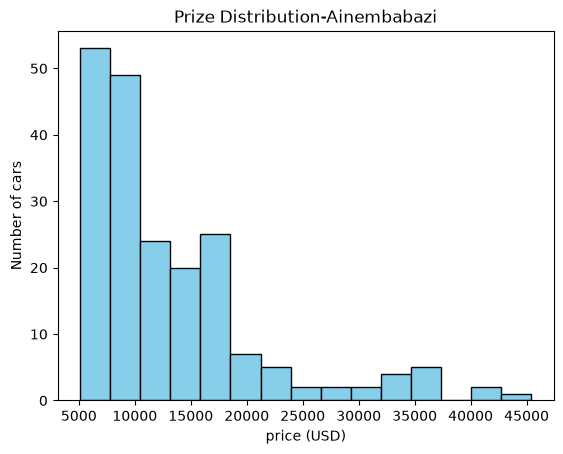

In [16]:
#Graphs
import matplotlib.pyplot as plt
plt.hist(df['price'],bins=15 , color='skyblue',edgecolor='black')
plt.title('Prize Distribution-Ainembabazi')
plt.xlabel('price (USD)')
plt.ylabel('Number of cars')
plt.show()

The car price distribution is right-skewed(positively skewed). The majority of the cars are concentrated in the lower price range of 5,000 to 20,000 with the highest. The frequency decreases sharply after $20,000.This shows that the dataset is dominated by cheap cars . Expensive cars are outliers.

In [19]:
#Question 3
#Grouping by drive-wheels
import matplotlib.pyplot as plt


In [30]:
#Grouping by drive-wheels
drive_price=df.groupby('drive-wheels')['price'].mean().sort_values(ascending=False)
body_price=df.groupby('body-style')['price'].mean().sort_values(ascending=False)
print ("Average price by drive-wheels:")
print(drive_price)
print(body_price)


Average price by drive-wheels:
drive-wheels
rwd    19757.613333
4wd    10241.000000
fwd     9244.779661
Name: price, dtype: float64
body-style
hardtop        22208.500000
convertible    21890.500000
sedan          14459.755319
wagon          12371.960000
hatchback       9957.441176
Name: price, dtype: float64


Average price by drive-wheels shows rwd is the most expensive (19,757),while fwd (9,244)is the cheapest

In [24]:
#Grouping by body-style
body_price=df.groupby('body-style')['price'].mean().sort_values(ascending=False)
print ("\nAverage price by body-style:")
print(body_price)


Average price by body-style:
body-style
hardtop        22208.500000
convertible    21890.500000
sedan          14459.755319
wagon          12371.960000
hatchback       9957.441176
Name: price, dtype: float64


Average price by body-style sorted in descending order shows that hardtop (22,208)is most expensive followed by convertible (21,890) and hatchback(9,957)is the cheapest.

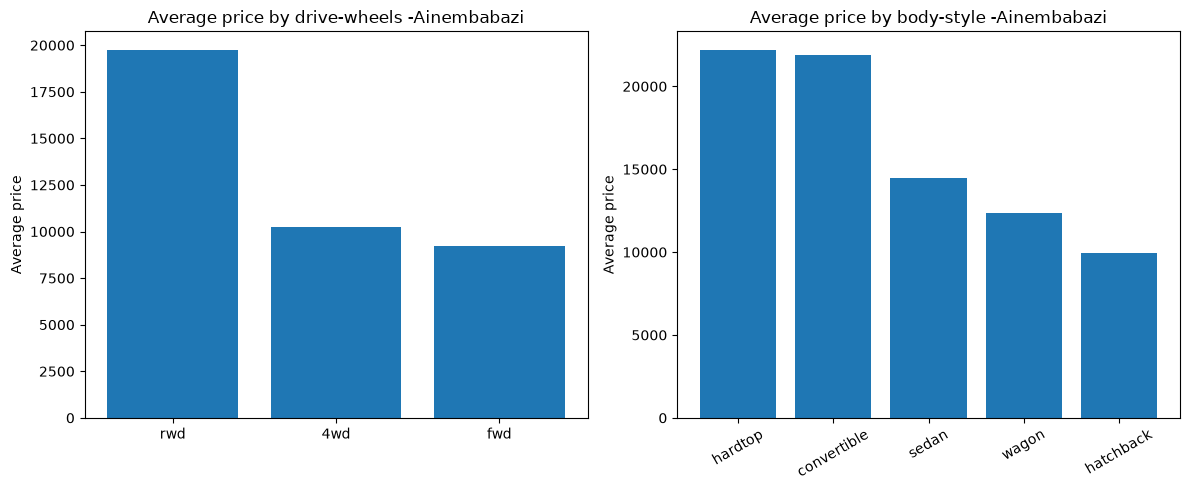

In [31]:
#Visusals
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.bar(drive_price.index,drive_price.values)
plt.title('Average price by drive-wheels -Ainembabazi')
plt.ylabel('Average price')   
plt.subplot (1,2,2)
plt.bar(body_price.index,body_price.values)
plt.title('Average price by body-style -Ainembabazi')
plt.ylabel('Average price')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Average price bt drive-wheels shows rwd is most expensive and fwd is cheapest. Average price by body-style shows hardtop and convetible are most expensive and hatchback is cheapest.

In [ ]:
# 4A.continuos variable vs price 
#correlation
numeric_cols=['engine-size', 'horsepower','curb-weight','city-mpg','highway-mpg','price']
print(df[numeric_cols].corr()['price'].sort_values(ascending=False))

price          1.000000
engine-size    0.872335
curb-weight    0.834415
horsepower     0.809575
city-mpg      -0.686571
highway-mpg   -0.704692
Name: price, dtype: float64


Price has strongest positive correlation with engine-size (0.87) , curb-weight(0.83) and horsepower (0.80) and price has negative correlation with city-mpg (-0.68) and highway-mpg (-0.70).This indicates that more fuel efficient cars are cheaper

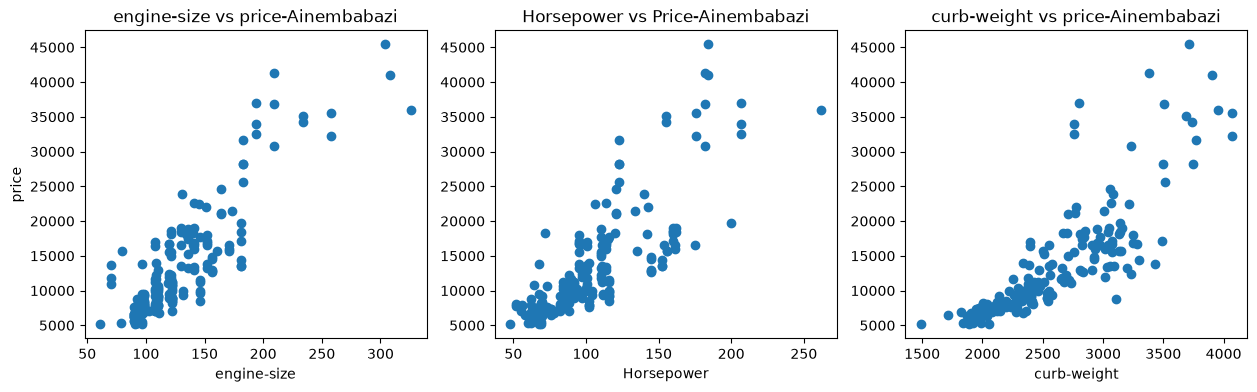

In [18]:
 #Visuals (Scatter Plots)
import matplotlib.pyplot as plt
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.scatter(df['engine-size'], df['price']) 
plt.title('engine-size vs price-Ainembabazi')
plt.xlabel('engine-size')
plt.ylabel('price')
plt.subplot(1,3,2)
plt.scatter(df['horsepower'], df['price'])
plt.title('Horsepower vs Price-Ainembabazi')
plt.xlabel('Horsepower')
plt.subplot(1,3,3)
plt.scatter(df['curb-weight'], df['price'])
plt.title('curb-weight vs price-Ainembabazi')
plt.xlabel('curb-weight')
plt.show()

In [ ]:
## Interpretation
### Engine-size vs price
Strong positive correlation, price increases as engine-size increases
### Horsepower vs price
Strong positive correlation, price increases as horsepower increases
### Curb-weight vs price
Strong positive correlation, price increases as Curb-weight increases
In conclusion, all three numeric variable increase price.Engine-size and horsepower are the strongest predictors.


In [ ]:
#4B.categorical variable vs price
print(df.groupby('fuel-system')['price'].mean())
print(df.groupby('body-style')['price'].mean())
print(df.groupby('drive-wheels')['price'].mean())

fuel-system
1bbl     7555.545455
2bbl     7433.203125
4bbl    12145.000000
idi     15838.150000
mfi     12964.000000
mpfi    17605.141304
spdi    10990.444444
spfi    11048.000000
Name: price, dtype: float64
body-style
convertible    21890.500000
hardtop        22208.500000
hatchback       9957.441176
sedan          14459.755319
wagon          12371.960000
Name: price, dtype: float64
drive-wheels
4wd    10241.000000
fwd     9244.779661
rwd    19757.613333
Name: price, dtype: float64


Fuel-system mpfi and idi have the highest average price (17,605 and 15,838) , whereas 2bbl and 1bbl have the lowest (7,433 and 7,555). Body-style hardtop (22.208) and convertible(21,890) are most expensive, hatchback(9,957) is cheapest.Drive-wheels rwd is most expensive conpared to 4wd and fwd.

body-style   drive-wheels
convertible  fwd             11595.000000
             rwd             23949.600000
hardtop      fwd              8249.000000
             rwd             24202.714286
hatchback    4wd              7603.000000
             fwd              8396.387755
             rwd             14337.777778
sedan        4wd             12647.333333
             fwd              9811.800000
             rwd             21711.833333
wagon        4wd              9095.750000
             fwd              9997.333333
             rwd             16994.222222
Name: price, dtype: float64


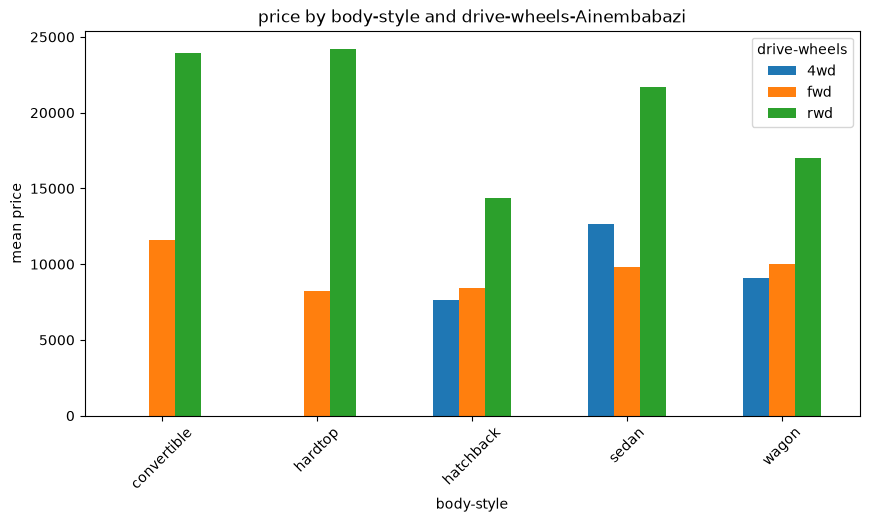

In [32]:
#4C.Two categorical variables 
import matplotlib.pyplot as plt
print (df.groupby(['body-style','drive-wheels'])['price'].mean())
df.groupby(['body-style','drive-wheels'])['price'].mean().unstack().plot(kind='bar',figsize=(10,5))
plt.title('price by body-style and drive-wheels-Ainembabazi')
plt.ylabel('mean price')
plt.xticks(rotation=45)
plt.show()


## Interpretation
The mean price is highest for hardtop and convertable with rwd , and the lowest for hatchback  wih 4wd and fwd. Generally rwd has higher mean price than the fwd and 4wd across body styles.

Top 8 features ipacting price;:
engine-size     0.872335
curb-weight     0.834415
horsepower      0.809575
city-L/100km    0.789898
width           0.751265
length          0.690628
wheel-base      0.584642
bore            0.543155
Name: price, dtype: float64


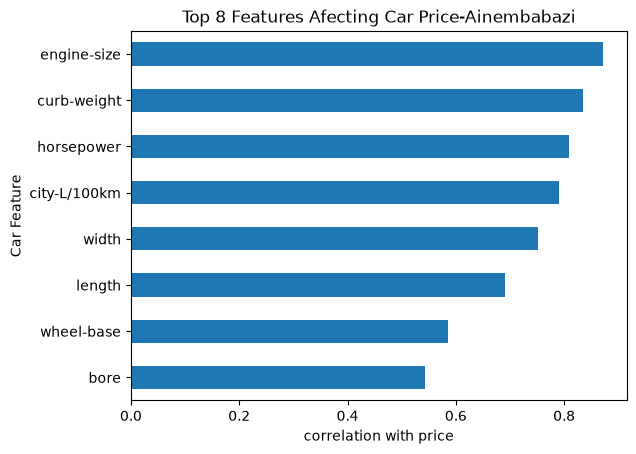

In [14]:
#Question 5
## Main variables that affect car price 
corr=df.corr(numeric_only=True)['price'].drop('price').sort_values(ascending=False)
print("Top 8 features ipacting price;:")
print(corr.head(8))
corr.head(8).sort_values().plot(kind='barh')
plt.xlabel('correlation with price')
plt.ylabel('Car Feature')
plt.title('Top 8 Features Afecting Car Price-Ainembabazi')
plt.show()

The findings from the figure show that engine-size , curb-weight and horsepower are the main drivers of price with correlation above 0.8 .
## Recommendation
Dealer should set high price for cars with large engine-size , heavy curb-weight and high horsepower and for low price , stock small engine, light cars.